In [2]:
%matplotlib inline
import datacube, numpy as np, pandas as pd, matplotlib.pyplot as plt
from deafrica_tools.plotting import plot_lulc

dc = datacube.Datacube(app="landcover_change")

lat = 7.31112
lon = -1.57730
buffer = 0.1

res = 100   # metres

ds = dc.load(product="io_lulc_v2",
             x=(lon - buffer, lon + buffer), y=(lat - buffer, lat + buffer),
             time=("2017", "2023"), measurements="classification",
             resolution=(-res, res), output_crs="epsg:6933", resampling="mode")
print(ds.time.values)    # shows which years are available

['2017-07-02T11:59:59.997500000' '2018-07-02T11:59:59.997500000'
 '2019-07-02T11:59:59.997500000' '2020-07-01T23:59:59.997500000'
 '2021-07-02T11:59:59.997500000' '2022-07-02T11:59:59.997500000'
 '2023-07-02T11:59:59.997500000']


In [3]:
# Area (km²) of each class in each year
names = ds.classification.flags_definition['data']['values']
area_per_pixel = res**2 / 1e6

rows = {}
for t in ds.time.values:
    codes, counts = np.unique(ds.classification.sel(time=t).values, return_counts=True)
    rows[str(t)[:4]] = {names[str(int(c))]: n * area_per_pixel for c, n in zip(codes, counts)}

table = pd.DataFrame(rows).fillna(0).round(1)
table['Change (km²)'] = (table.iloc[:, -1] - table.iloc[:, 0]).round(1)
table['Change (%)'] = (table['Change (km²)'] / table.iloc[:, 0] * 100).round(1)
table

,2017,2018,2019,2020,2021,2022,2023,Change (km²),Change (%)
trees,135.8,125.4,93.5,67.8,92.9,108.7,137.0,1.2,0.9
crops,67.7,62.9,72.2,72.4,86.3,76.6,41.4,-26.3,-38.8
built area,8.3,7.8,8.1,8.8,9.3,9.7,10.1,1.8,21.7
rangeland,281.0,296.8,318.9,343.7,304.3,297.8,304.3,23.3,8.3


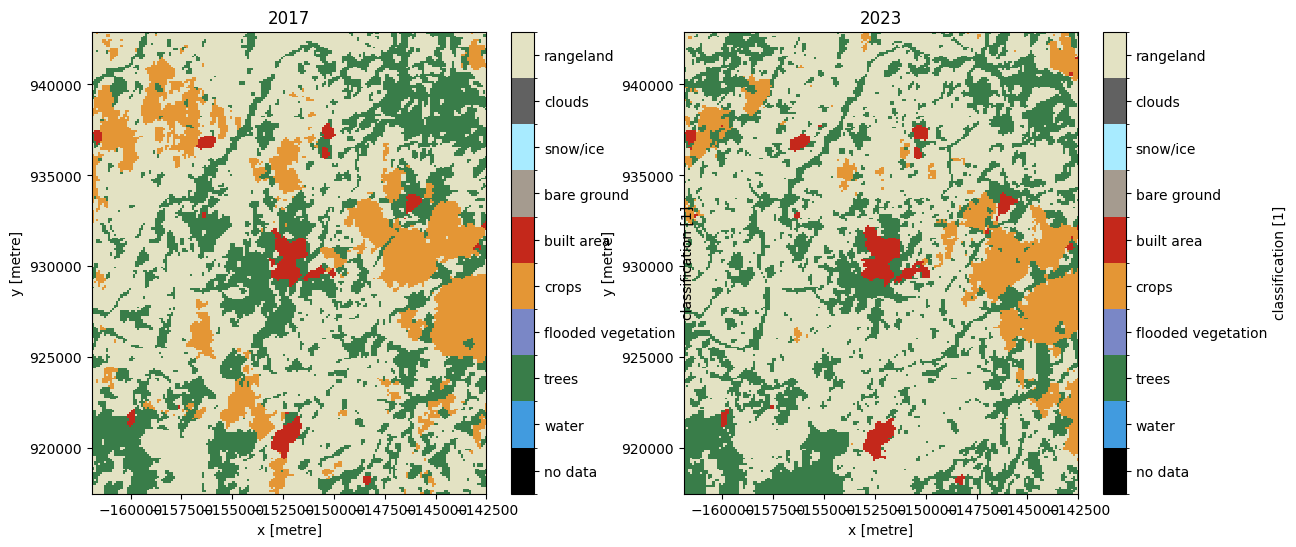

In [4]:
# Maps: first year vs last year
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
plot_lulc(ds.classification.isel(time=0), product="IO", legend=True, ax=ax[0])
plot_lulc(ds.classification.isel(time=-1), product="IO", legend=True, ax=ax[1])
ax[0].set_title(str(ds.time.values[0])[:4]); ax[1].set_title(str(ds.time.values[-1])[:4]);

## Findings

Annual ESRI land cover maps (2017 to 2023) show cropland rising from 67.7 km² to a peak of 86.3 km² in 2021 (+27%), then falling to 41.4 km² in 2023, a net loss of 39% against 2017. Built-up area grew steadily from 8.3 to 10.1 km² (+22%), while tree cover (136 to 137 km²) and rangeland (281 to 304 km²) changed little overall, although they swapped area between years, suggesting some classification noise. The cropland peak in 2021 coincides with the September 2021 NDVI dip, but rainfall that month was the highest of the year, so the dip is not explained by drought or by land cover change. NDVI peaks stayed similar in 2023, so the mapped crop decline probably reflects fallow fields or classification differences rather than crop failure.